In [61]:
import pandas as pd
import numpy as np
import seaborn as sns    # To load iris dataset


pd.set_option('display.float_format', '{:.4f}'.format)
np.set_printoptions(suppress=True, precision=4)

In [62]:
df = sns.load_dataset('iris')

df.sample(5)

,sepal_length,sepal_width,petal_length,petal_width,species
116,6.5000,3.0000,5.5000,1.8000,virginica
19,5.1000,3.8000,1.5000,0.3000,setosa
95,5.7000,3.0000,4.2000,1.2000,versicolor
18,5.7000,3.8000,1.7000,0.3000,setosa
50,7.0000,3.2000,4.7000,1.4000,versicolor


<Axes: xlabel='sepal_length', ylabel='Density'>

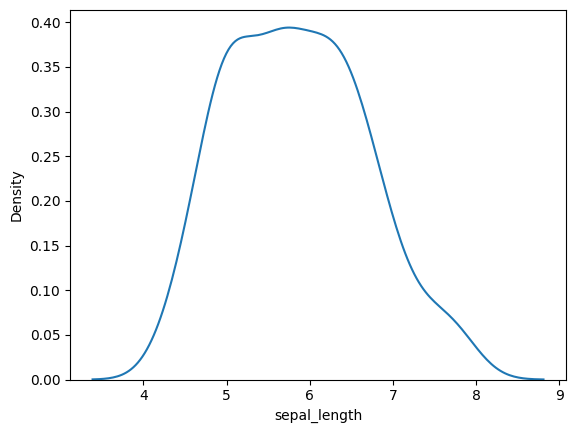

In [63]:
sns.kdeplot(df['sepal_length'])

See, distribution of `sepal_length` is sort of normal. But we dont know how much normal it is. So, see the below code.

# We will check if `sepal_length` has a normal distribution or not.

* **Step 1:** Take some data having normal distribution <br>
* **Step 2:** Find its `n` percentiles.
---
* **Step 3:** Find `n` percentiles of `sepal_length`.
* **Step 4:** Plot scatterplot of percentiles of both the data

In [64]:
nd_data = np.random.normal(loc = 0, scale = 1, size = 1000)
nd_data[0:5]

# loc: Mean of the data
# Scale: Standard Deviation of the data.

array([-0.1448,  0.0702,  0.2326,  0.5762, -0.4685])

In [65]:
# Calculating percentiles of nd_data

per_nd_data = []

for i in range(1, 101):
    per = np.percentile(nd_data, i)
    per_nd_data.append(per)

print(per_nd_data[0:5])

[-2.3847603480231525, -2.112757741665064, -1.941686506462572, -1.7954352183531566, -1.6413883588168423]


In [66]:
# Calculating percentiles of sepal_length

per_sepal_length = []

for i in range(1, 101):
    per = np.percentile(df['sepal_length'], i)
    per_sepal_length.append(per)

print(per_sepal_length[0:5])

[4.4, 4.4, 4.547, 4.6, 4.6]


<Axes: >

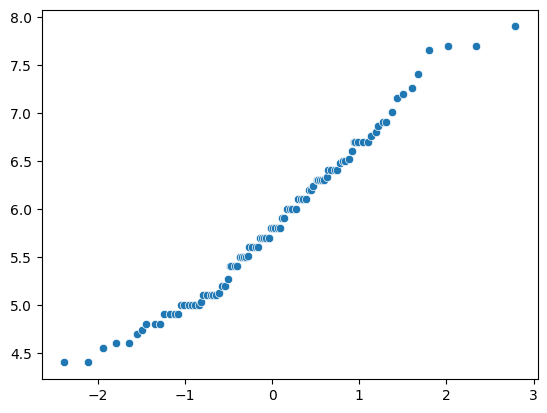

In [67]:
# plotting scatter plot

sns.scatterplot(x = per_nd_data, y = per_sepal_length)
# sns.lineplot(x = per_nd_data, y = per_sepal_length)

# We do not need to calculate these things manually. We have tools.

Text(0.5, 1.0, 'Sepal Length: QQ Plot')

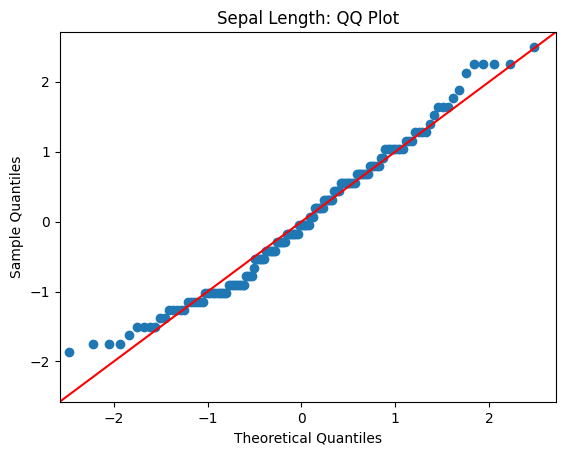

In [68]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Create a QQ plot
fig = sm.qqplot(df['sepal_length'], line = '45', fit = True)

# Adding title and labels
plt.title("Sepal Length: QQ Plot")

# Here, in x-axis, it is ND Percentiles and
# In y-axis, it is sepal_length's percentile

# 2) Check Uniform Distribution.

* It is not like we can only check Normal Distribution in `qqplot()`, we can check any distribution.
* `qqplot()` bydefault takes normal data as theoretical data

In [69]:
# Generating uniform distribution data

uniform_data = np.random.uniform(low = 1, high = 100, size = 1000)
uniform_data[0:10]

array([51.7885, 26.3637, 97.2868, 68.4809, 34.8913, 41.611 , 39.9122,
       46.8126, 12.0104, 99.5528])

(array([ 99.,  90.,  98., 100., 101., 114.,  99.,  99., 101.,  99.]),
 array([ 1.0688, 10.9474, 20.826 , 30.7045, 40.5831, 50.4617, 60.3403,
        70.2189, 80.0975, 89.9761, 99.8547]),
 <BarContainer object of 10 artists>)

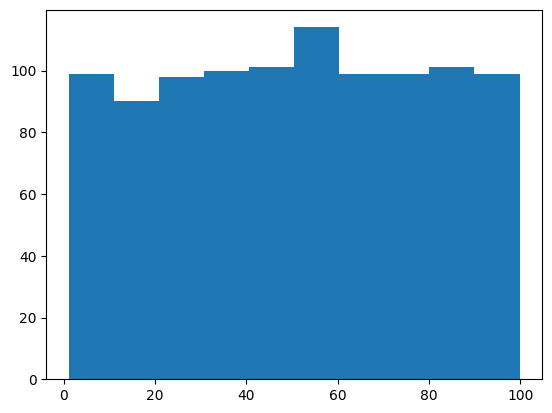

In [70]:
# Ploting the data to check if it  truly has a Uniform Distribution
plt.hist(uniform_data) 

# Almost Uniform Distribution

In [71]:
import scipy.stats as stats

Text(0.5, 1.0, 'QQ Plot to verify Uniform Distribution')

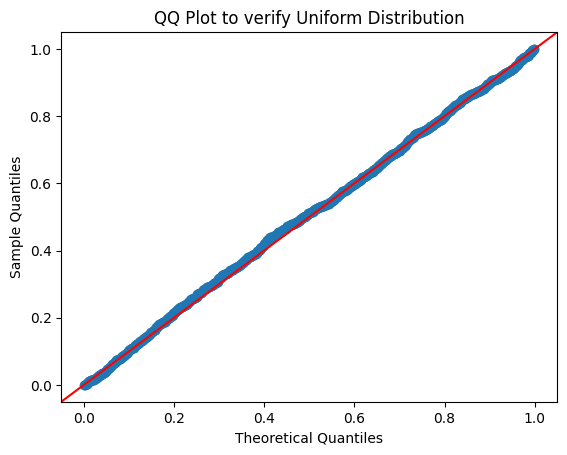

In [72]:
# Create a qqplot using uniform distribution

fig = sm.qqplot(data = uniform_data, dist = stats.uniform, fit = True, line = '45')

plt.title("QQ Plot to verify Uniform Distribution")

See, all points  lie on a line, means our `theoretical data` has a Uniform Distribution.

# 3) Log Normal Distribution:

If for any `column` say `X`, distribution of `log(X) (log of all values)` is `Normal`, `X` is said to have  `Log Normal Distribution`

* QQ Plot: The best method to check if any data has `Log Normal Distribution`.

# 4) Pareto Distribution

* QQ Plot: The best method to check if any data has `Pareto Distribution`.

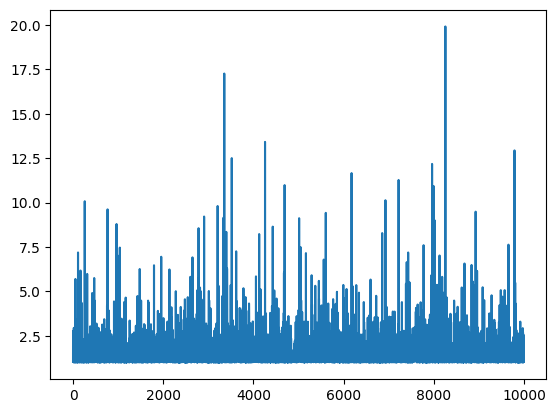

In [73]:
# Generating Pareto data
xm = 100
data_pareto = (np.random.pareto(3, 10000) + 1) * 1
plt.plot(data_pareto)


Text(0.5, 1.0, 'QQ plot to check Pareto Distribution')

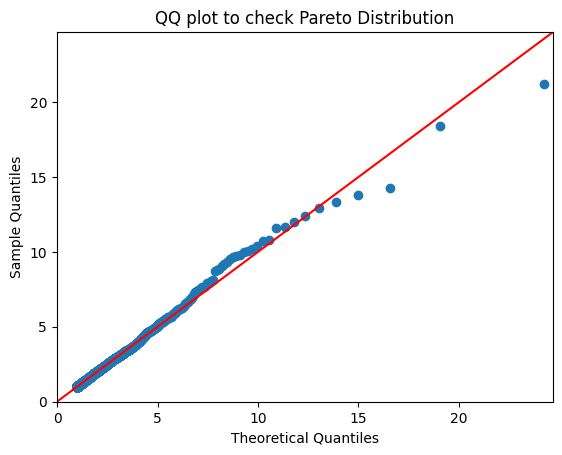

In [74]:
sm.qqplot(data = data_pareto, dist = stats.pareto, fit = True, line = '45')
plt.title("QQ plot to check Pareto Distribution")

# Part 2: Transformers

**Note**:
  * We should always deal with missing values before applying transformers because if we fill missing values later, distribution
  may change
  * Applying these transformers are just one line of code. So we should apply all these and select the one which gives us the best accuracy.

1) `Log Transformer:`
    * Applicable when in a column, all the data points are positive and the distribution is right skewed
2) `Square Transformer:`
    * This squares all the values of a column and it is found more effective in `left sqewed data`.
3) `Reciprocal and Square root Transformer`: Apply these two as well and see the results.



In [75]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
import statsmodels.api as sm 

In [76]:
df = pd.read_csv(r"00_titanic.csv", usecols = ['Age', 'Fare', 'Survived'])

print(f"""
{df.head()}
{'-' * 50}
{df.isnull().sum()}""")


   Survived     Age    Fare
0         0 22.0000  7.2500
1         1 38.0000 71.2833
2         1 26.0000  7.9250
3         1 35.0000 53.1000
4         0 35.0000  8.0500
--------------------------------------------------
Survived      0
Age         177
Fare          0
dtype: int64


In [77]:
# Filling missing values in column Age with mean
df.fillna(value = {'Age': df['Age'].mean()}, inplace = True)

print(df.isnull().sum())

Survived    0
Age         0
Fare        0
dtype: int64


# Before Transformation

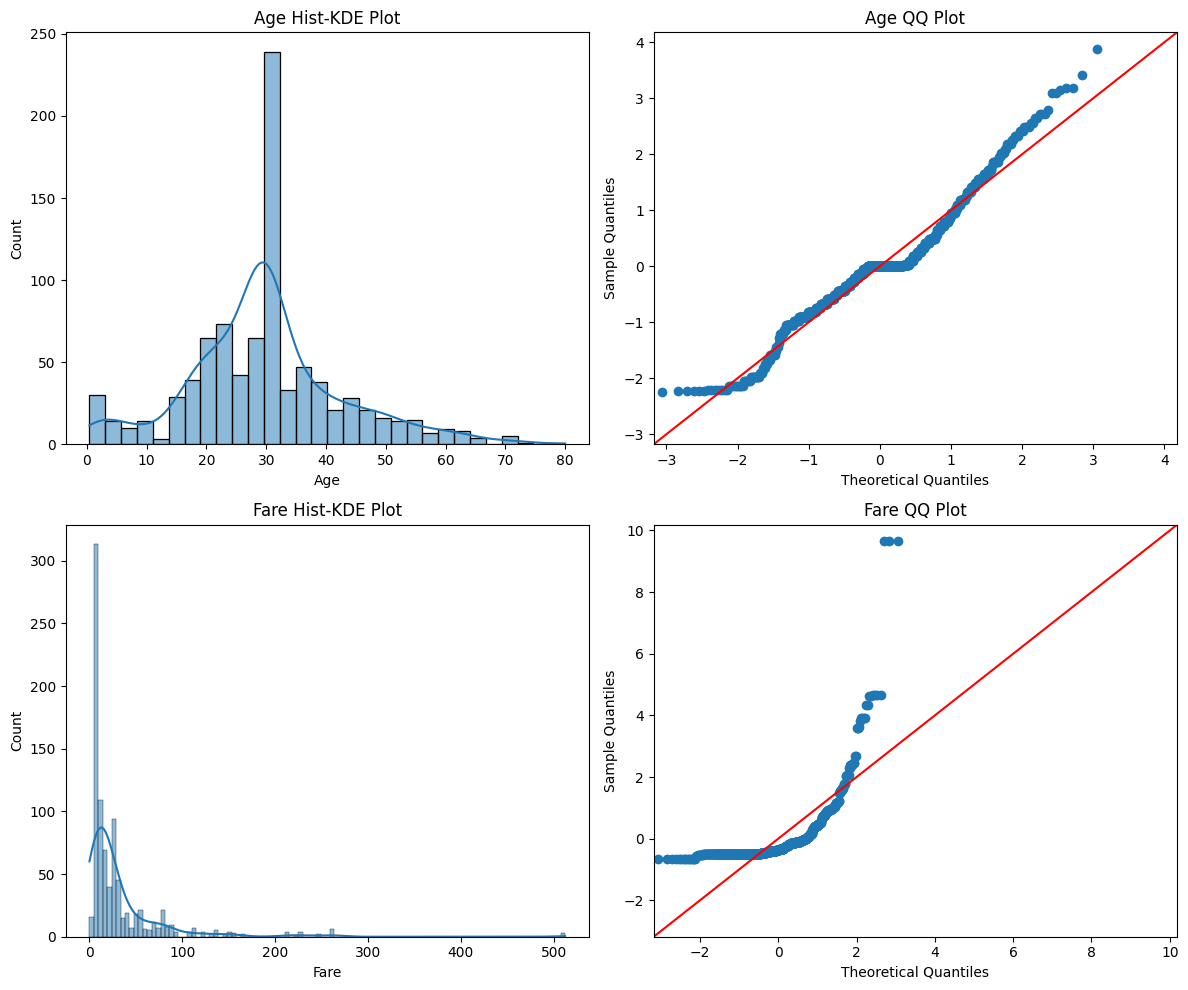

In [78]:
# Creating (2,2) frid
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (12,10))

# axes

# figsize(width, height)

# --------------- Age ---------------

axes[0,0].set_title("Age Hist-KDE Plot")
sns.histplot(df['Age'], kde = True, ax = axes[0,0])

axes[0,1].set_title("Age QQ Plot")
sm.qqplot(data = df['Age'], dist = stats.norm, fit = True, line = '45', ax = axes[0,1])

# --------------- Fare ---------------

axes[1,0].set_title("Fare Hist-KDE Plot")
sns.histplot(df['Fare'], kde = True, ax = axes[1,0])

axes[1,1].set_title("Fare QQ Plot")
sm.qqplot(data = df['Fare'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 1])

# Layout fix
plt.tight_layout()

plt.show()


# Conclusion:
* Age column is somewhat normal but not perfectly normal.
* Fair column is Right Skewed, so we should apply Log Transformer

`We will apply all four transformers in both the columns and` <br> 
`see which transformer transforms to normal distribution better than the others.`

# After Transformation

In [79]:
# Creating objects for transformer

log_trans = FunctionTransformer(func = np.log1p)    # np.log1p bcz it will add 1 first and then find log. This is bcz log(0) is not possible and will throw an error.
square_trans = FunctionTransformer(func = np.square)
sqrt_trans = FunctionTransformer(func = np.sqrt)
reciprocal_trans = FunctionTransformer(func = lambda x: 1/( x+1))    # 1/(x+1) bcz if any value of x is 0, 1/0 will throw error.

# Creating list of tuples for Transformers
transformers = [
    ('orig', 'passthrough', ['Age', 'Fare']),    # Without this, it will remove original Age and Fare column.
    ('log', log_trans, ['Age', 'Fare']),
    ('square', square_trans, ['Age', 'Fare']),
    ('sqrt', sqrt_trans, ['Age', 'Fare']),
    ('reciprocal', reciprocal_trans, ['Age', 'Fare'])
]

# Creatinf ColumnTransformer
ct = ColumnTransformer(
    transformers = transformers,
    remainder = 'passthrough'  # Other columns where no transformation is performed, leave it as it is.
)

# Applying ColumnTransformer

transformed_data = ct.fit_transform(df)

transformed_data

array([[22.    ,  7.25  ,  3.1355, ...,  0.0435,  0.1212,  0.    ],
       [38.    , 71.2833,  3.6636, ...,  0.0256,  0.0138,  1.    ],
       [26.    ,  7.925 ,  3.2958, ...,  0.037 ,  0.112 ,  1.    ],
       ...,
       [29.6991, 23.45  ,  3.4242, ...,  0.0326,  0.0409,  0.    ],
       [26.    , 30.    ,  3.2958, ...,  0.037 ,  0.0323,  1.    ],
       [32.    ,  7.75  ,  3.4965, ...,  0.0303,  0.1143,  0.    ]])

In [80]:
print(df.shape, transformed_data.shape)

(891, 3) (891, 11)


In [81]:
columns = [

    # Original
    'orig_age',
    'orig_fare',

    # Log
    'log_age',
    'log_fare',

    # Square
    'square_age',
    'square_fare',

    # Sqrt
    'sqrt_age',
    'sqrt_fare',

    # Reciprocal
    'reciprocal_age',
    'reciprocal_fare',

    # Remaining columns
    'survived'
]

df2 = pd.DataFrame(transformed_data, columns=columns)

df2.head()

df2 = pd.DataFrame(transformed_data, columns=columns)

df2.head()

,orig_age,orig_fare,log_age,log_fare,square_age,square_fare,sqrt_age,sqrt_fare,reciprocal_age,reciprocal_fare,survived
0,22.0000,7.2500,3.1355,2.1102,484.0000,52.5625,4.6904,2.6926,0.0435,0.1212,0.0000
1,38.0000,71.2833,3.6636,4.2806,1444.0000,5081.3089,6.1644,8.4429,0.0256,0.0138,1.0000
2,26.0000,7.9250,3.2958,2.1889,676.0000,62.8056,5.0990,2.8151,0.0370,0.1120,1.0000
3,35.0000,53.1000,3.5835,3.9908,1225.0000,2819.6100,5.9161,7.2870,0.0278,0.0185,1.0000
4,35.0000,8.0500,3.5835,2.2028,1225.0000,64.8025,5.9161,2.8373,0.0278,0.1105,0.0000


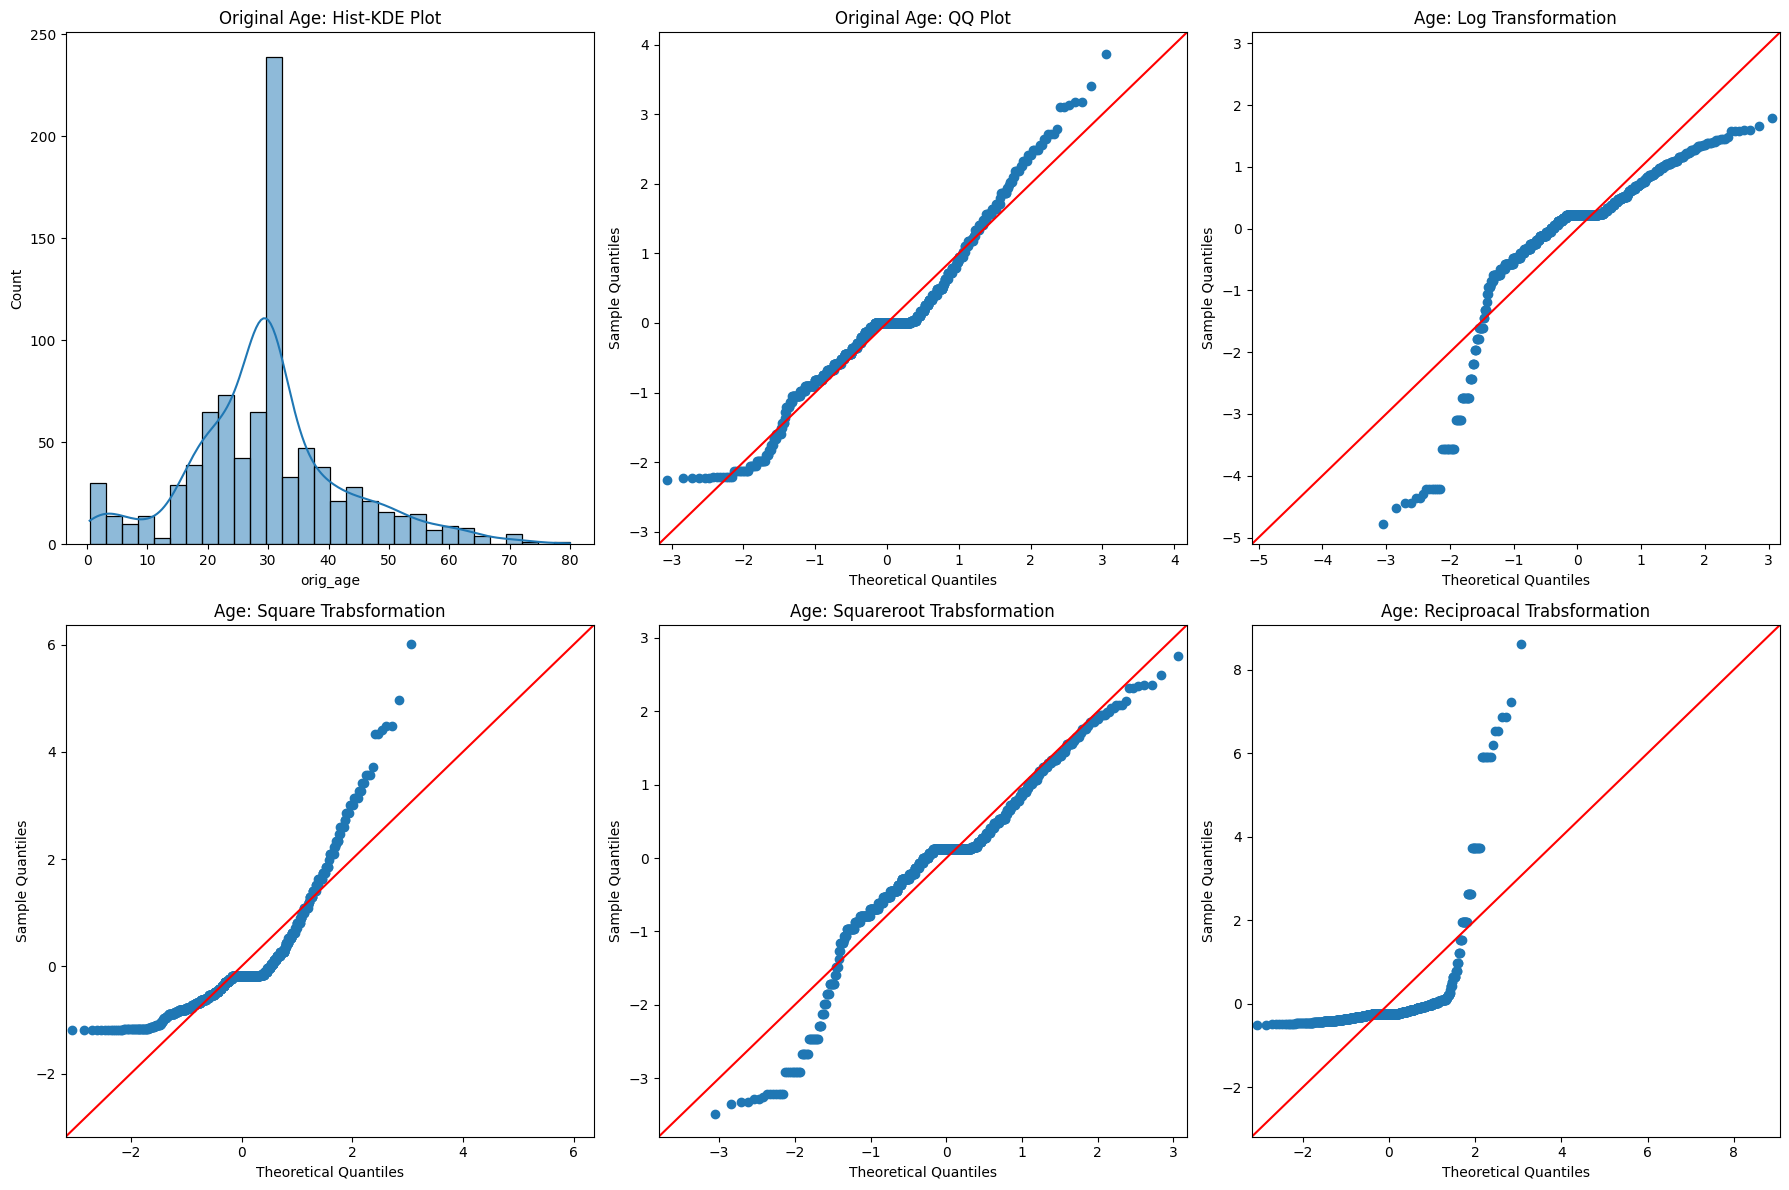

In [82]:
# Creating (2,2) grid
fig, axes = plt.subplots(nrows = 2, ncols = 3, figsize = (18,12))

# axes

# figsize(width, height)

# --------------- Age ---------------

axes[0,0].set_title("Original Age: Hist-KDE Plot")
sns.histplot(df2['orig_age'], kde = True, ax = axes[0,0])

axes[0,1].set_title("Original Age: QQ Plot")
sm.qqplot(data = df2['orig_age'], dist = stats.norm, fit = True, line = '45', ax = axes[0,1])

# --------------- After Transformation ---------------

axes[0,2].set_title("Age: Log Transformation")
sm.qqplot(data = df2['log_age'], dist = stats.norm, fit = True, line = '45', ax = axes[0, 2])

axes[1,0].set_title("Age: Square Trabsformation")
sm.qqplot(data = df2['square_age'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 0])

axes[1,1].set_title("Age: Squareroot Trabsformation")
sm.qqplot(data = df2['sqrt_age'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 1])


axes[1,2].set_title("Age: Reciproacal Trabsformation")
sm.qqplot(data = df2['reciprocal_age'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 2])


# Layout fix
plt.tight_layout()

plt.show()


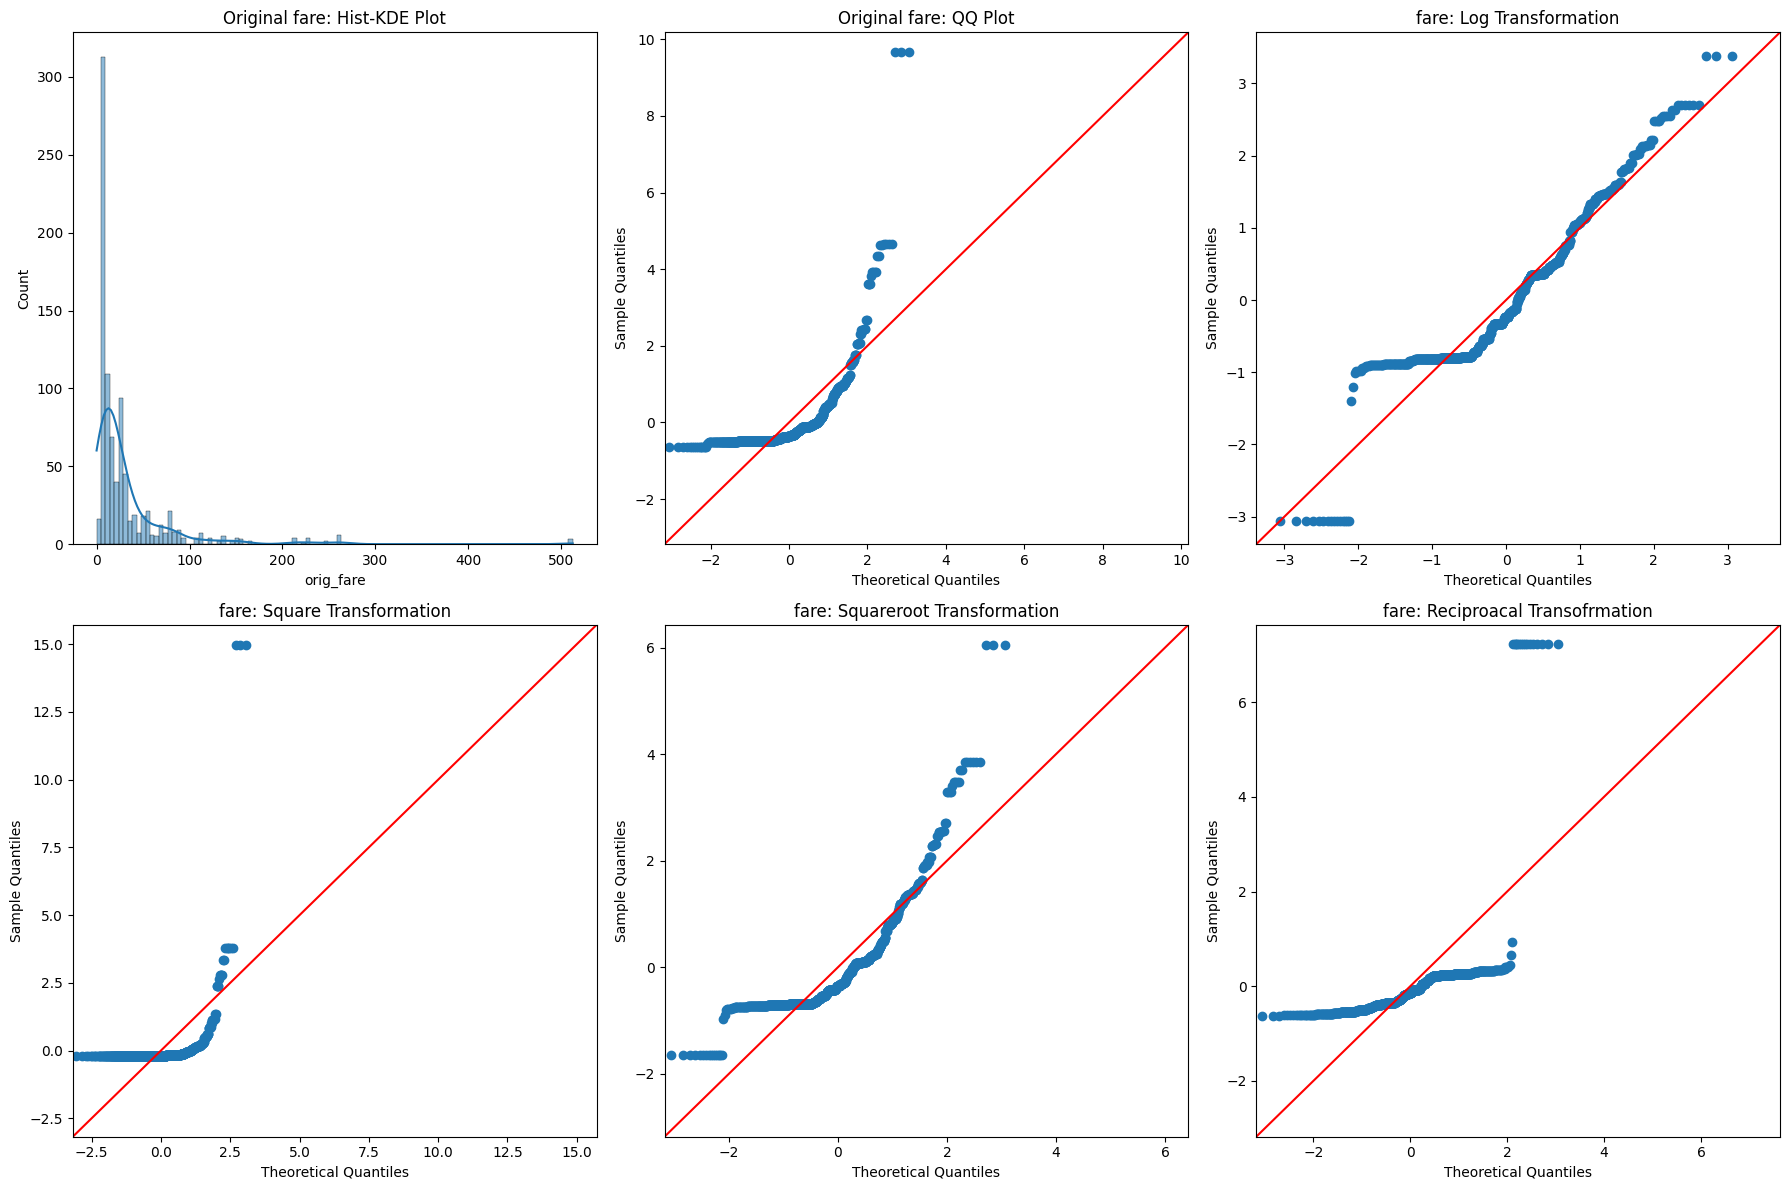

In [ ]:
# Creating (2,2) grid
fig, axes = plt.subplots(nrows = 2, ncols = 3, figsize = (18,12))

# axes

# figsize(width, height)

# --------------- fare ---------------

axes[0,0].set_title("Original Fare: Hist-KDE Plot")
sns.histplot(df2['orig_fare'], kde = True, ax = axes[0,0])

axes[0,1].set_title("Original Fare: QQ Plot")
sm.qqplot(data = df2['orig_fare'], dist = stats.norm, fit = True, line = '45', ax = axes[0,1])

# --------------- After Transformation ---------------

axes[0,2].set_title("Fare: Log Transformation")
sm.qqplot(data = df2['log_fare'], dist = stats.norm, fit = True, line = '45', ax = axes[0, 2])

axes[1,0].set_title("Fare: Square Transformation")
sm.qqplot(data = df2['square_fare'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 0])

axes[1,1].set_title("Fare: Squareroot Transformation")
sm.qqplot(data = df2['sqrt_fare'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 1])


axes[1,2].set_title("Fare: Reciproacal Transofrmation")
sm.qqplot(data = df2['reciprocal_fare'], dist = stats.norm, fit = True, line = '45', ax = axes[1, 2])


# Layout fix
plt.tight_layout()

plt.show()


`Observation:` 
* See, we are geeting normal distribution for Fare in log transformation only.
* We know the reason, **bcz Fair column was right skewed**

# See the change in accuracy after transformer

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [85]:
x = df.iloc[:, 1:]
y = df['Survived']

lr = LogisticRegression()

accuracies = cross_val_score(estimator = lr, X = x, y = y, scoring = 'accuracy', cv = 10)
print(f"Accuracy_Before_Transformation: {np.mean(accuracies)}")

Accuracy_Before_Transformation: 0.6589013732833957


In [86]:
def apply_transformer(transformer):
    x = df.iloc[:, 1:]
    y = df['Survived']

    # Transforming only Fare column as it is much right skewed
    # Age has almost Normal Distribution

    trans = [
        ('fare_trans', FunctionTransformer(transformer), ['Fare'])
    ]
    ct = ColumnTransformer(transformers = trans, remainder = 'passthrough')

    x_transformed = ct.fit_transform(x)

    # Training the model
    lr = LogisticRegression()

    accuracies = cross_val_score(estimator = lr, X = x_transformed, y = y, scoring = 'accuracy', cv = 10)
    print(f"Accuracy: {np.mean(accuracies)}")

    # Plotting Fare After Transforming

    fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (12,5))

    axes[0].set_title("Fare Before Transformation")
    sm.qqplot(data = df['Fare'], dist = stats.norm, line = '45', fit = True, ax = axes[0])

    axes[1].set_title("Fare After Transformation")
    sm.qqplot(data = x_transformed[:, 0], dist = stats.norm, line = '45', fit = True, ax = axes[1])

    plt.tight_layout()
    plt.show()

Accuracy: 0.6712609238451936


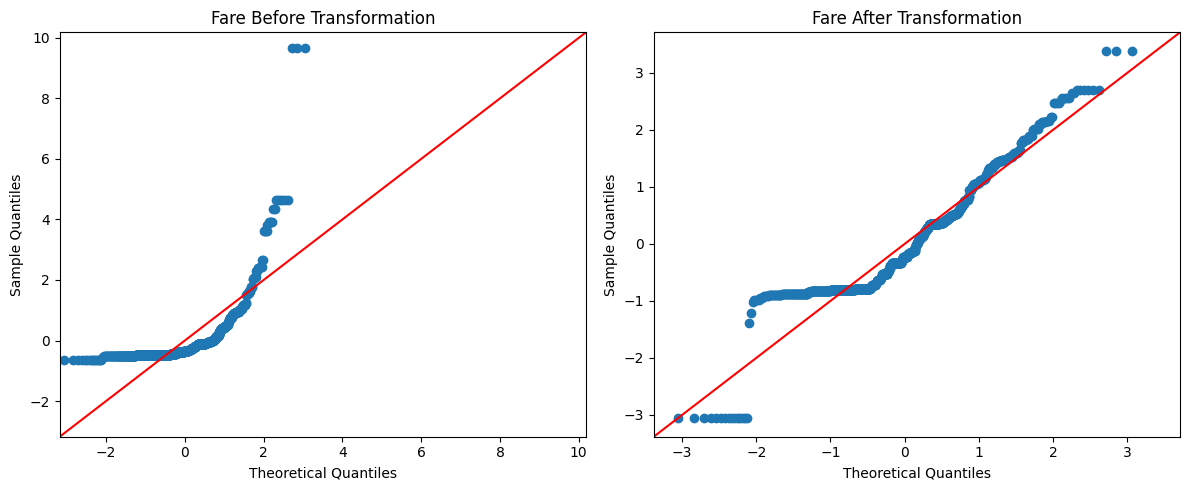

In [87]:
apply_transformer(transformer = np.log1p)

Survived    0.0000
Age        22.0000
Fare        7.2500
Name: 0, dtype: float64

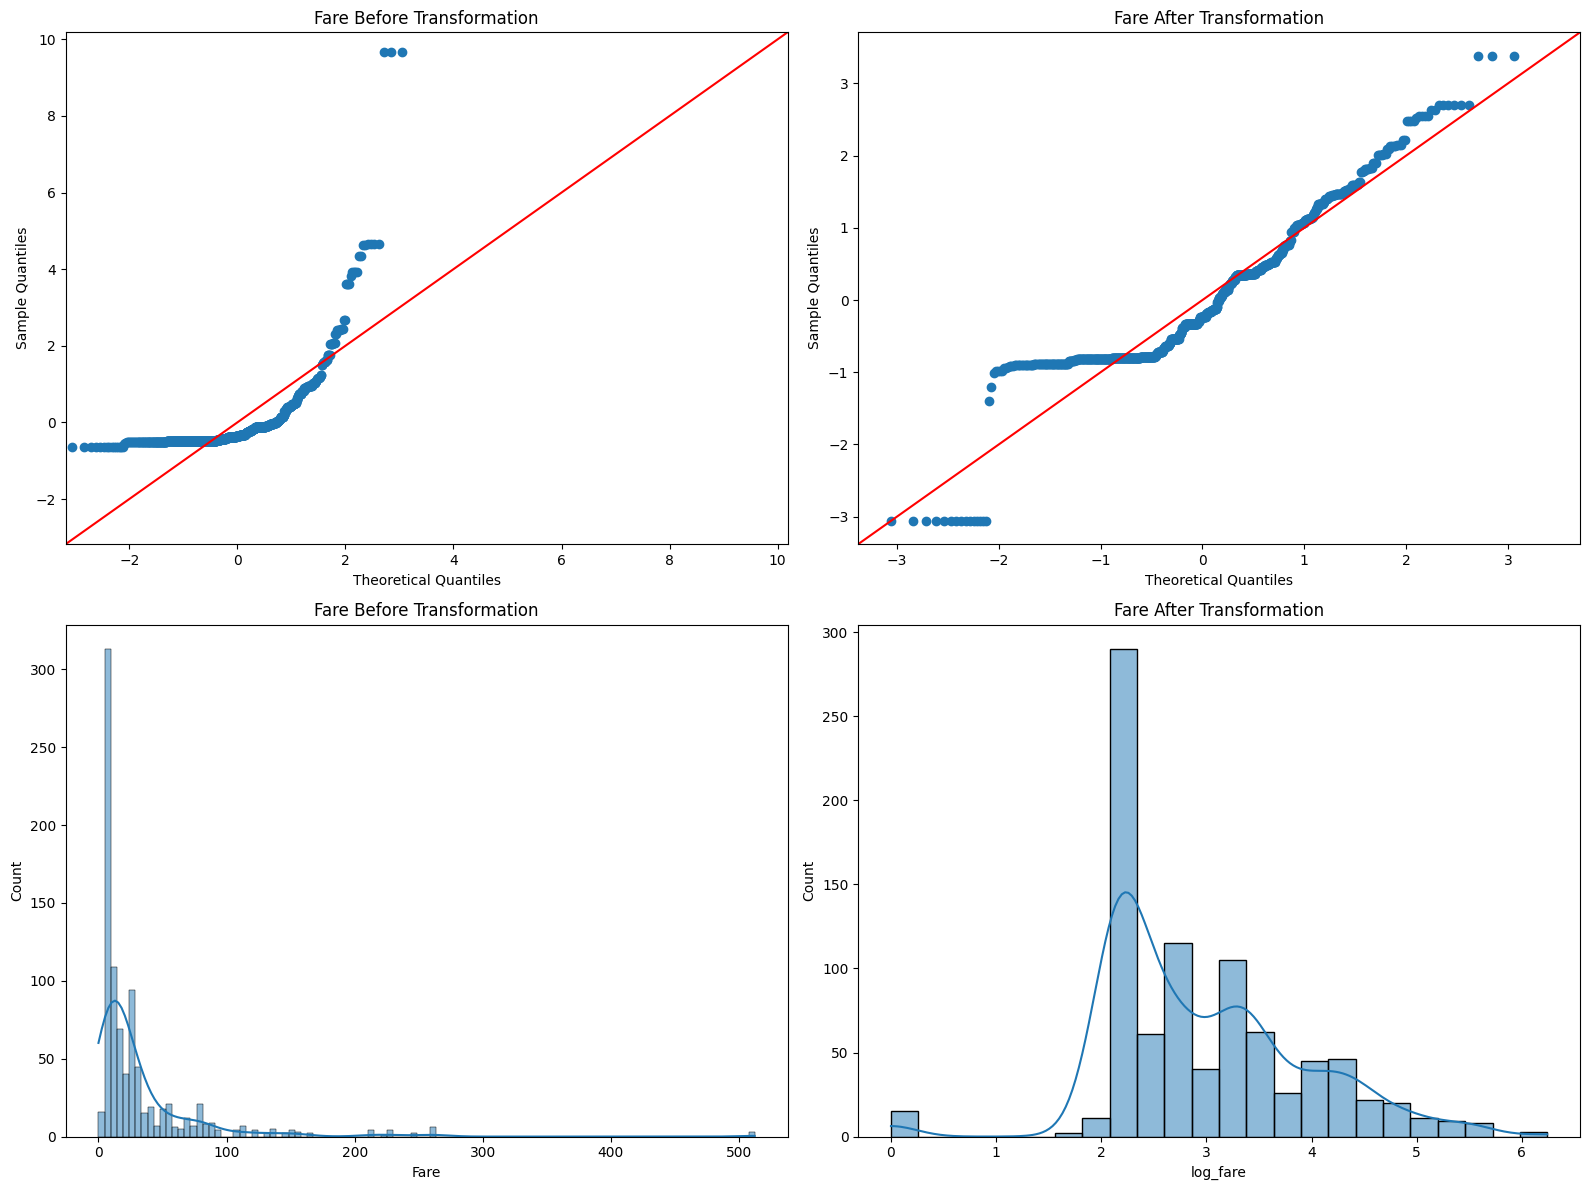

In [93]:
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (16, 12))

axes[0, 0].set_title("Fare Before Transformation")
sm.qqplot(data = df['Fare'], dist = stats.norm, line = '45', fit = True, ax = axes[0, 0])

axes[0, 1].set_title("Fare After Transformation")
sm.qqplot(data = df2['log_fare'], dist = stats.norm, line = '45', fit = True, ax = axes[0, 1])

axes[1, 0].set_title("Fare Before Transformation")
sns.histplot(data = df['Fare'], kde = True, ax = axes[1, 0])

axes[1, 1].set_title("Fare After Transformation")
sns.histplot(data = df2['log_fare'], kde = True, ax = axes[1, 1])

plt.tight_layout()
plt.show()

`Observation:` 
* See, we are geeting allmost normal distribution for Fare in after log transformation.
* We know the reason, **bcz Fair column was right skewed**

In [94]:
df2

,orig_age,orig_fare,log_age,log_fare,square_age,square_fare,sqrt_age,sqrt_fare,reciprocal_age,reciprocal_fare,survived
0,22.0000,7.2500,3.1355,2.1102,484.0000,52.5625,4.6904,2.6926,0.0435,0.1212,0.0000
1,38.0000,71.2833,3.6636,4.2806,1444.0000,5081.3089,6.1644,8.4429,0.0256,0.0138,1.0000
2,26.0000,7.9250,3.2958,2.1889,676.0000,62.8056,5.0990,2.8151,0.0370,0.1120,1.0000
3,35.0000,53.1000,3.5835,3.9908,1225.0000,2819.6100,5.9161,7.2870,0.0278,0.0185,1.0000
4,35.0000,8.0500,3.5835,2.2028,1225.0000,64.8025,5.9161,2.8373,0.0278,0.1105,0.0000
...,...,...,...,...,...,...,...,...,...,...,...
886,27.0000,13.0000,3.3322,2.6391,729.0000,169.0000,5.1962,3.6056,0.0357,0.0714,0.0000
887,19.0000,30.0000,2.9957,3.4340,361.0000,900.0000,4.3589,5.4772,0.0500,0.0323,1.0000
888,29.6991,23.4500,3.4242,3.1966,882.0376,549.9025,5.4497,4.8425,0.0326,0.0409,0.0000
889,26.0000,30.0000,3.2958,3.4340,676.0000,900.0000,5.0990,5.4772,0.0370,0.0323,1.0000


# Note:
* Instead of `QQ Plot` we can also use `scipy.stats.probplot`.
*  If we give `fit = True`, probplot fits the regression line and returns `(slope, intercept and r2 score) of a column plotted`
* We can try it.
* If we know any one `QQ Plot` or `Prob Plot` we will never stuck in any work.

# Next Session:
We will see some other popular `Transformers`